# 📊 Carbono en tránsito — Parte 2: visualización

**Autor de esta parte:** Luis Andrés Santos Cortés (ID: 45297)

**Integrantes del grupo:** Luis Fabián Ulloa Rodríguez (45210) · Luis Andrés Santos Cortés (45297) · Michelle Andrea Murillo Gonzalez (37858)


**Pregunta del proyecto:** ¿Colombia es importador o exportador neto de CO₂ por el comercio, y cómo ha cambiado desde 1990 hasta el último año disponible?

**Gráfico del artículo usado:** *Share of CO₂ emissions embedded in trade*, del artículo [CO₂ and Greenhouse Gas Emissions](https://ourworldindata.org/co2-emissions) de Our World in Data. Datos: [enlace del gráfico](https://ourworldindata.org/grapher/share-co2-embedded-in-trade).

**¿Cómo se lee el dato?**
- **Positivo:** el país importa más CO₂ del que exporta (importador neto).
- **Negativo:** el país exporta más CO₂ del que importa (exportador neto).
- Está dado como **% de las emisiones que el país produce**.

> 💡 **Cómo leer este cuaderno:** antes de cada bloque de código hay un texto que explica *qué hace*. Dentro del código, cada línea con `#` es un comentario que explica el paso. Para ejecutar un bloque: selecciónalo y presiona **Shift + Enter**. Se ejecutan **en orden, de arriba hacia abajo**.

> Este cuaderno es una de las 3 partes. Parte 1: carga y limpieza (Luis Fabián). Parte 3: modelo e interpretación (Michelle).

## 1. Librerías
**¿Qué hace?** Una librería es una caja de herramientas ya hecha. Las importamos para no programar todo desde cero.

In [1]:
import pandas as pd                 # pandas: para trabajar con tablas de datos
import matplotlib.pyplot as plt     # matplotlib: para hacer gráficos

## 2. Cargar los datos
**¿Qué hace?** Descarga el archivo CSV directamente de Our World in Data y lo convierte en una tabla llamada `datos`. Se necesita internet.

*Si no hay internet:* descarga el CSV desde la página del gráfico (botón *Download*), ponlo en la misma carpeta y cambia la línea de `pd.read_csv(...)` por `datos = pd.read_csv("emisiones_comercio_co2.csv")`.

In [2]:
# Enlace del archivo CSV de Our World in Data
url = "https://ourworldindata.org/grapher/share-co2-embedded-in-trade.csv?v=1&csvType=full&useColumnShortNames=false"

# Leemos el archivo y lo guardamos en la variable "datos"
datos = pd.read_csv(url, storage_options={"User-Agent": "Our World In Data data fetch/1.0"})

# Guardamos una copia en el computador (por si luego no hay internet)
datos.to_csv("emisiones_comercio_co2.csv", index=False)

# Mostramos las primeras 5 filas
datos.head()

,Entity,Code,Year,Share of annual CO₂ emissions embedded in trade
0,Africa,OWID_AFR,1990,-1.149361
1,Africa,OWID_AFR,1991,-2.982905
2,Africa,OWID_AFR,1992,-0.305387
3,Africa,OWID_AFR,1993,-1.342971
4,Africa,OWID_AFR,1994,-2.414056


## 3. Limpieza rápida
**¿Qué hace?** Es la misma limpieza de la Parte 1: nombres simples, sin repetidos ni vacíos, y solo Colombia.

In [3]:
# 1. Ponemos nombres de columnas más simples
datos.columns = ["pais", "codigo", "año", "porcentaje"]

# 2. Quitamos filas repetidas
datos = datos.drop_duplicates()

# 3. Quitamos filas que no tienen valor en "porcentaje"
datos = datos.dropna(subset=["porcentaje"])

# 4. Nos quedamos solo con Colombia y la ordenamos por año
colombia = datos[datos["pais"] == "Colombia"].sort_values("año")

print("Filas totales después de limpiar:", len(datos))
print("Años de datos de Colombia:", len(colombia))
colombia.head()

Filas totales después de limpiar: 4851
Años de datos de Colombia: 35


,pais,codigo,año,porcentaje
875,Colombia,COL,1990,6.006888
876,Colombia,COL,1991,4.837586
877,Colombia,COL,1992,8.713652
878,Colombia,COL,1993,7.575504
879,Colombia,COL,1994,6.829249


## 4. Visualización

**Gráfico 1 — Colombia por año.** La línea punteada en 0 separa dos casos: arriba, importador neto; abajo, exportador neto.

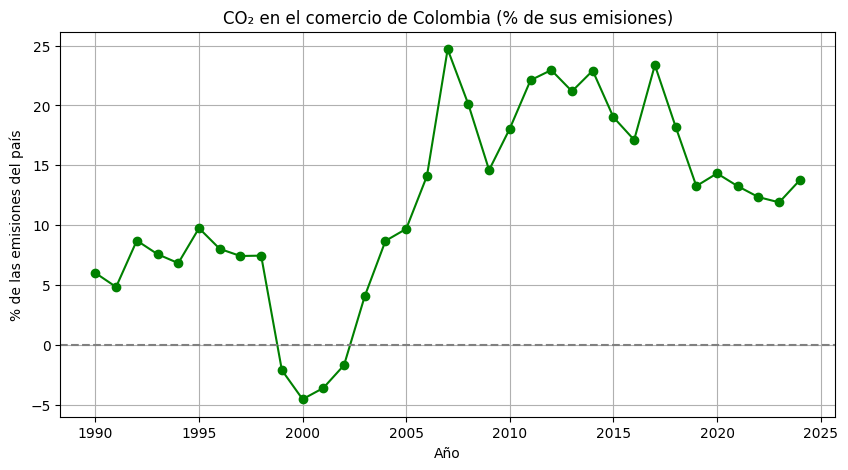

Valor más alto: 24.7 % en 2007
Valor más bajo: -4.5 % en 2000


In [4]:
plt.figure(figsize=(10, 5))                                              # tamaño del gráfico
plt.plot(colombia["año"], colombia["porcentaje"], color="green", marker="o")   # línea de Colombia
plt.axhline(0, color="gray", linestyle="--")                             # línea en 0 (separa importador / exportador)
plt.title("CO₂ en el comercio de Colombia (% de sus emisiones)")
plt.xlabel("Año")
plt.ylabel("% de las emisiones del país")
plt.grid(True)
plt.show()

# Año con el valor más alto y más bajo
mayor = colombia.loc[colombia["porcentaje"].idxmax()]
menor = colombia.loc[colombia["porcentaje"].idxmin()]
print(f"Valor más alto: {mayor['porcentaje']:.1f} % en {int(mayor['año'])}")
print(f"Valor más bajo: {menor['porcentaje']:.1f} % en {int(menor['año'])}")

**Gráfico 2 — Colombia comparada con otros países de América.**

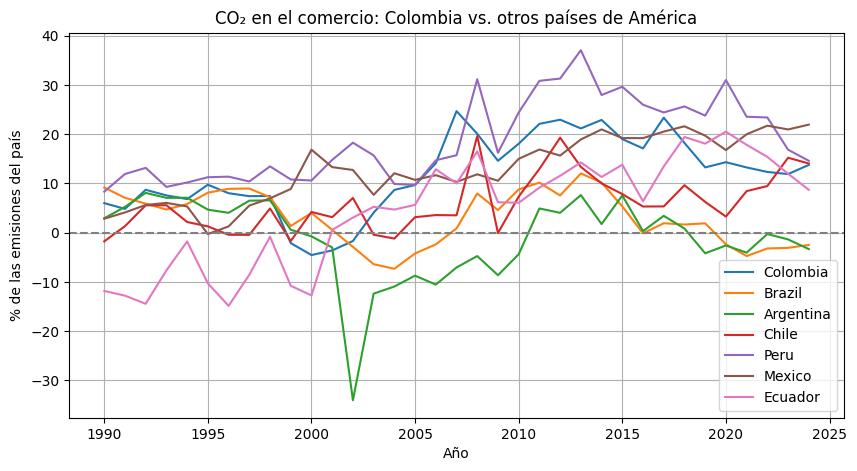

In [5]:
# Países que vamos a comparar (los nombres vienen en inglés, como en los datos)
paises = ["Colombia", "Brazil", "Argentina", "Chile", "Peru", "Mexico", "Ecuador"]

plt.figure(figsize=(10, 5))
for p in paises:                                  # repetimos para cada país de la lista
    d = datos[datos["pais"] == p]                 # filas de ese país
    plt.plot(d["año"], d["porcentaje"], label=p)  # dibujamos su línea
plt.axhline(0, color="gray", linestyle="--")
plt.title("CO₂ en el comercio: Colombia vs. otros países de América")
plt.xlabel("Año")
plt.ylabel("% de las emisiones del país")
plt.legend()
plt.grid(True)
plt.show()

**Gráfico 3 — Los 10 mayores importadores y exportadores.** Se usa el último año disponible y se quitan regiones y continentes.

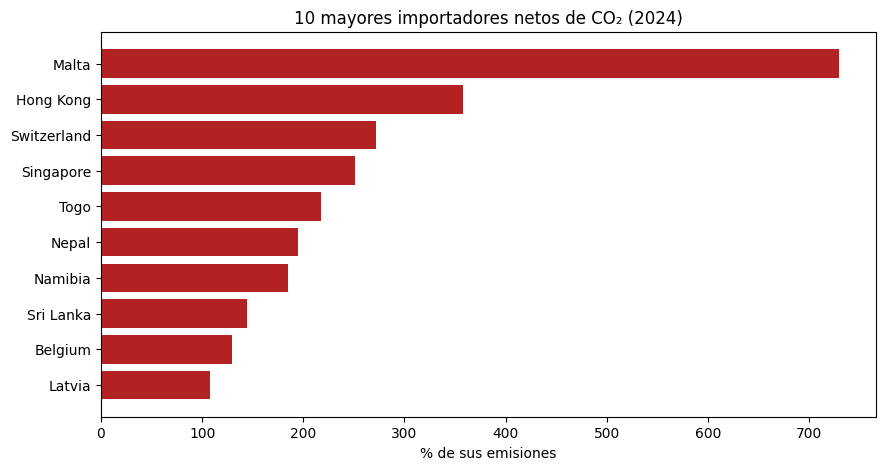

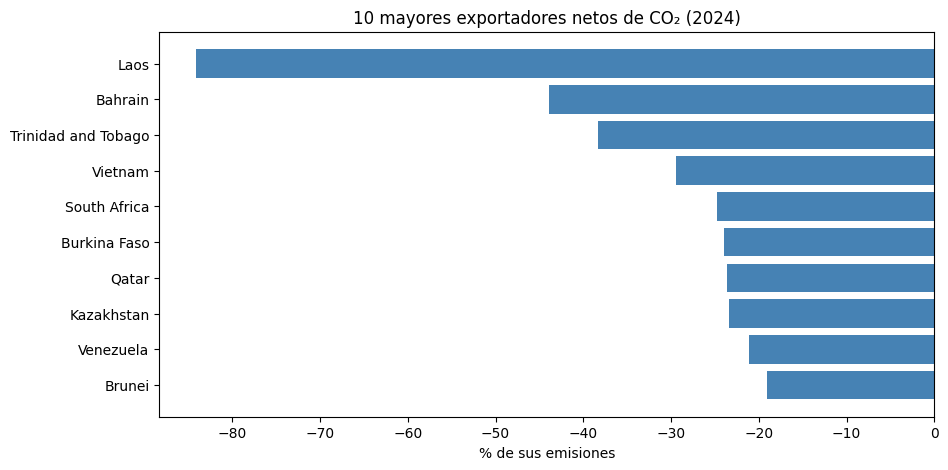

Colombia ocupa el puesto 76 de 120 países en 2024.


In [6]:
# Quitamos regiones y continentes (sus códigos empiezan por "OWID") para dejar solo países
solo_paises = datos[datos["codigo"].notna()]
solo_paises = solo_paises[~solo_paises["codigo"].str.startswith("OWID")]

# Usamos el último año disponible
ultimo_año = solo_paises["año"].max()
tabla = solo_paises[solo_paises["año"] == ultimo_año]

# Los 10 valores más altos (importadores) y los 10 más bajos (exportadores)
importadores = tabla.sort_values("porcentaje", ascending=False).head(10)
exportadores = tabla.sort_values("porcentaje", ascending=True).head(10)

# Gráfico de los importadores
plt.figure(figsize=(10, 5))
plt.barh(importadores["pais"], importadores["porcentaje"], color="firebrick")
plt.gca().invert_yaxis()     # el más alto queda arriba
plt.title(f"10 mayores importadores netos de CO₂ ({ultimo_año})")
plt.xlabel("% de sus emisiones")
plt.show()

# Gráfico de los exportadores
plt.figure(figsize=(10, 5))
plt.barh(exportadores["pais"], exportadores["porcentaje"], color="steelblue")
plt.gca().invert_yaxis()
plt.title(f"10 mayores exportadores netos de CO₂ ({ultimo_año})")
plt.xlabel("% de sus emisiones")
plt.show()

# ¿En qué puesto quedó Colombia? (1 = el que más importa)
orden = tabla.sort_values("porcentaje", ascending=False).reset_index(drop=True)
fila = orden[orden["pais"] == "Colombia"]
if len(fila) > 0:
    print(f"Colombia ocupa el puesto {fila.index[0] + 1} de {len(orden)} países en {ultimo_año}.")

## ✅ Conclusiones de la visualización

- El **Gráfico 1** muestra si Colombia estuvo por encima de 0 (importador neto) o por debajo de 0 (exportador neto) en cada año.
- El **Gráfico 2** permite comparar a Colombia con otros países de América.
- El **Gráfico 3** muestra los extremos: quienes más importan y quienes más exportan CO₂. Los valores muy altos suelen ser de economías pequeñas que dependen mucho del comercio.

## 📘 Mini glosario

- **Importador neto:** país que trae (importa) más CO₂ en los productos de lo que envía (exporta).
- **Limpieza de datos:** quitar lo que estorba: filas repetidas, valores vacíos, columnas con nombres difíciles.